# 1조 — 최종 연체 예측 소프트 보팅 모델
원본 데이터부터 전처리, 학습, 평가, 모델 저장까지 위에서 아래로 실행합니다. Python 3.10.11과 동봉한 requirements.txt를 사용하세요. cs-training.csv를 이 노트북과 같은 폴더에 둡니다.

**선택된 모델:** XGBoost 32% + LightGBM 48% + Random Forest 20%. 검증 AP 목표는 **0.419658**입니다. 사진에 사용된 분류 임계값 **0.4147656988432002**를 고정합니다. AP와 ROC-AUC는 임계값 없이 예측 확률로 계산합니다.

학습/검증/테스트는 60/20/20으로 나눕니다. 이 제출본에서는 추가 탐색 없이 기존 설정을 재현합니다. 검증 데이터는 과거 모델·가중치 선택에 사용되었으며, 테스트도 이전 보고 과정에서 확인한 데이터이므로 완전히 새로운 외부 검증으로 해석하지 않습니다.

In [1]:
# 1. 라이브러리와 고정 설정
from pathlib import Path
import sys, json, hashlib, warnings
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, log_loss, confusion_matrix,
    precision_recall_curve, roc_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED, N_JOBS = 42, 4
THRESHOLD = 0.4147656988432002
WEIGHTS = {"XGBoost": 0.32, "LightGBM": 0.48, "RandomForest": 0.20}
DATA_PATH = Path("cs-training.csv")  # 다른 위치라면 이 경로만 수정
OUTPUT = Path("results")
OUTPUT.mkdir(exist_ok=True)
packages = ["numpy", "pandas", "scipy", "scikit-learn", "xgboost",
            "lightgbm", "joblib", "matplotlib"]
environment = {name: metadata.version(name) for name in packages}
print("Python:", sys.version.split()[0])
display(pd.Series(environment, name="설치 버전").to_frame())

Python: 3.10.11


,설치 버전
numpy,1.23.5
pandas,1.5.3
scipy,1.9.3
scikit-learn,1.0.2
xgboost,1.7.6
lightgbm,4.5.0
joblib,1.6.0
matplotlib,3.6.3


## 2. 데이터와 전처리
- 타깃은 2년 내 심각한 연체 여부(0/1), ID는 제외합니다.
- 나이 0인 1행을 제거합니다. 부양가족 수를 포함합니다.
- 원래 30~59일 연체 횟수의 96/98을 나타내는 '이상' 변수를 추가합니다.
- 기존 최종 모델 재현 규칙: 30~59일·90일 이상 연체 횟수의 96/98은 24로, 60~89일의 96/98은 12로 바꿉니다. 이는 특수코드의 실제 의미가 확인되었다는 뜻은 아닙니다.
- 소득·부양가족 결측값은 지금 채우지 않습니다. 분할 후 각 파이프라인에서 **Train 중앙값 + 결측 여부 지표**로 처리합니다.
- 그 밖의 극단값 삭제, 로그 변환, 표준화는 적용하지 않습니다.

In [2]:
# 원본 열 순서를 명시하여 재현성을 유지합니다.
required = ["SeriousDlqin2yrs", "RevolvingUtilizationOfUnsecuredLines", "age",
    "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio", "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines", "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"]
translations = dict(zip(required, ["2년 내 심각한 연체 여부", "무담보 신용한도 사용률",
    "나이", "30~59일 연체 횟수", "부채 비율", "월 소득", "개설된 신용거래 수",
    "90일 이상 연체 횟수", "부동산 대출·신용한도 수", "60~89일 연체 횟수", "부양가족 수"]))
if not DATA_PATH.is_file():
    raise FileNotFoundError("cs-training.csv를 현재 작업 폴더에 두세요: " + str(Path.cwd()))
raw = pd.read_csv(DATA_PATH)
data = raw.loc[raw["age"].ne(0), required].copy().reset_index(drop=True)
data = data.rename(columns=translations)
data["이상"] = np.select(
    [data["30~59일 연체 횟수"].eq(96), data["30~59일 연체 횟수"].eq(98)],
    [1, 2], default=0)
for col in ["30~59일 연체 횟수", "90일 이상 연체 횟수"]:
    data.loc[data[col].isin([96, 98]), col] = 24
data.loc[data["60~89일 연체 횟수"].isin([96, 98]), "60~89일 연체 횟수"] = 12
TARGET = "2년 내 심각한 연체 여부"
X, y = data.drop(columns=TARGET), data[TARGET].astype(int)
assert set(y.unique()) == {0, 1}
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("원본 / 전처리 후:", len(raw), "/", len(data), "행")
print("입력 변수:", X.shape[1], "/ 양성 비율:", round(y.mean(), 6))
print("원본 SHA256:", data_hash)
display(pd.DataFrame({"자료형": X.dtypes.astype(str), "결측 수": X.isna().sum()}))

원본 / 전처리 후: 150000 / 149999 행
입력 변수: 11 / 양성 비율: 0.06684
원본 SHA256: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac


,자료형,결측 수
무담보 신용한도 사용률,float64,0
나이,int64,0
30~59일 연체 횟수,int64,0
부채 비율,float64,0
월 소득,float64,29731
개설된 신용거래 수,int64,0
90일 이상 연체 횟수,int64,0
부동산 대출·신용한도 수,int64,0
60~89일 연체 횟수,int64,0
부양가족 수,float64,3924


In [3]:
# 3. 층화 분할: 분할 순서와 시드도 기존 최종 모델과 동일
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
splits = {"Train": (X_train, y_train), "Validation": (X_valid, y_valid),
          "Test": (X_test, y_test)}
assert X_train.index.intersection(X_valid.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_valid.index.intersection(X_test.index).empty
split_table = pd.DataFrame([{"구분": name, "행 수": len(a), "양성 수": int(b.sum()),
    "양성 비율": b.mean()} for name, (a, b) in splits.items()]).set_index("구분")
display(split_table)
positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())

,행 수,양성 수,양성 비율
구분,,,
Train,89999,6016,0.066845
Validation,30000,2005,0.066833
Test,30000,2005,0.066833


In [4]:
# 4. 이미 선택한 설정으로 Train만 학습합니다. 추가 탐색은 하지 않습니다.
estimators = {
    "XGBoost": XGBClassifier(n_estimators=350, learning_rate=0.02, max_depth=4,
        min_child_weight=15, subsample=0.8601, colsample_bytree=0.67611,
        gamma=0, reg_alpha=0, reg_lambda=1, scale_pos_weight=positive_weight,
        objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
        n_jobs=N_JOBS, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=350, learning_rate=0.027,
        num_leaves=12, max_depth=-1, min_child_samples=150,
        class_weight="balanced", reg_alpha=0.1, reg_lambda=10,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
        n_jobs=N_JOBS, random_state=SEED, verbosity=-1),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12,
        min_samples_leaf=30, min_samples_split=2, max_features="sqrt",
        max_samples=0.7, class_weight=None, bootstrap=True,
        random_state=SEED, n_jobs=N_JOBS)}
models = {}
for name, estimator in estimators.items():
    pipeline = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                         ("model", estimator)])
    pipeline.fit(X_train, y_train)
    models[name] = pipeline
    print(name, "학습 완료")
print("보팅 비중:", WEIGHTS)

XGBoost 학습 완료
LightGBM 학습 완료
RandomForest 학습 완료
보팅 비중: {'XGBoost': 0.32, 'LightGBM': 0.48, 'RandomForest': 0.2}


In [5]:
# 5. 모든 분할에 같은 모델·가중치·임계값을 적용합니다.
probabilities, metrics, matrices = {}, [], {}
component_rows = []
for name, (a, b) in splits.items():
    component = {model_name: model.predict_proba(a)[:, 1]
                 for model_name, model in models.items()}
    p = sum(WEIGHTS[k] * component[k] for k in WEIGHTS)
    pred = (p >= THRESHOLD).astype(int)
    probabilities[name] = p
    matrices[name] = confusion_matrix(b, pred, labels=[0, 1])
    metrics.append({"구분": name, "AP": average_precision_score(b, p),
        "ROC-AUC": roc_auc_score(b, p), "Accuracy": accuracy_score(b, pred),
        "Precision": precision_score(b, pred, zero_division=0),
        "Recall": recall_score(b, pred, zero_division=0),
        "F1": f1_score(b, pred, zero_division=0), "LogLoss": log_loss(b, p)})
    for k, cp in component.items():
        component_rows.append({"구분": name, "모델": k, "AP": average_precision_score(b, cp),
                               "ROC-AUC": roc_auc_score(b, cp)})
performance = pd.DataFrame(metrics).set_index("구분")
print("고정 임계값:", THRESHOLD)
display(performance.round(6))
gap = (performance.loc["Train"] - performance.loc["Test"]).to_frame("Train - Test")
print("성능 격차 (AP·ROC-AUC 등은 클수록 좋고 LogLoss는 작을수록 좋음)")
display(gap.round(6))
print("혼동행렬: 행=실제 0/1, 열=예측 0/1")
for name, matrix in matrices.items():
    print(name, matrix.tolist())
display(pd.DataFrame(component_rows).round(6))
expected_ap = 0.4196579357385778
print("기존 검증 AP 재현:", np.isclose(performance.loc["Validation", "AP"], expected_ap, atol=1e-9))
assert np.isclose(performance.loc["Validation", "AP"], expected_ap, atol=1e-6), "데이터·버전·설정 확인 필요"

고정 임계값: 0.4147656988432002


,AP,ROC-AUC,Accuracy,Precision,Recall,F1,LogLoss
구분,,,,,,,
Train,0.428368,0.876002,0.795198,0.217664,0.795545,0.341808,0.353131
Validation,0.419658,0.867908,0.795500,0.216112,0.784040,0.338830,0.354466
Test,0.402930,0.869330,0.795267,0.215670,0.782544,0.338147,0.354947


성능 격차 (AP·ROC-AUC 등은 클수록 좋고 LogLoss는 작을수록 좋음)


,Train - Test
AP,0.025438
ROC-AUC,0.006673
Accuracy,-0.000069
Precision,0.001994
Recall,0.013002
F1,0.003662
LogLoss,-0.001816


혼동행렬: 행=실제 0/1, 열=예측 0/1
Train [[66781, 17202], [1230, 4786]]
Validation [[22293, 5702], [433, 1572]]
Test [[22289, 5706], [436, 1569]]


,구분,모델,AP,ROC-AUC
0,Train,XGBoost,0.419557,0.872715
1,Train,LightGBM,0.411713,0.875724
2,Train,RandomForest,0.447969,0.887458
3,Validation,XGBoost,0.417418,0.866482
4,Validation,LightGBM,0.416171,0.868164
5,Validation,RandomForest,0.417553,0.867986
6,Test,XGBoost,0.402724,0.868639
7,Test,LightGBM,0.400453,0.869350
8,Test,RandomForest,0.399230,0.868021


기존 검증 AP 재현: True


## 6. 해석과 한계
AP는 연체 고객이 약 6.68%인 불균형 데이터의 주 평가 지표입니다. 검증 AP 0.419658은 정확도 41.97%라는 뜻이 아닙니다. 임계값은 사진의 값을 그대로 고정했으며 테스트 결과로 조정하지 않습니다.

Train과 Test의 차이만으로 과적합 유무를 단정할 수 없습니다. 아래 결과는 선택된 모델의 일반화 격차를 보여줍니다. 동일한 입력값 조합이 서로 다른 분할에도 존재할 수 있는 행 단위 무작위 분할이며, 고객 ID를 이용한 그룹 분할이나 시간 순 검증은 아닙니다. 특이값 처리 규칙과 검증 데이터의 반복 사용 역시 결과 해석의 제한입니다.

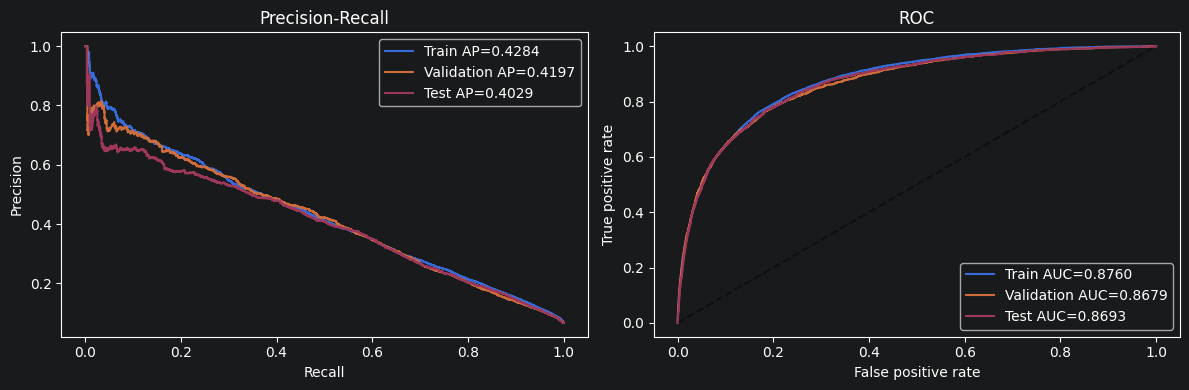

결과와 모델 저장 완료: C:\Users\KDT76\OneDrive\문서\MachineLearning\프로젝트1조\교수님제출_최고소프트보팅\results


In [6]:
# 7. 곡선 및 성능표 저장 — 그래프 글꼴 호환성을 위해 축은 영문 사용
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, b) in splits.items():
    p = probabilities[name]
    precision, recall, _ = precision_recall_curve(b, p)
    fpr, tpr, _ = roc_curve(b, p)
    axes[0].plot(recall, precision, label=f"{name} AP={performance.loc[name, 'AP']:.4f}")
    axes[1].plot(fpr, tpr, label=f"{name} AUC={performance.loc[name, 'ROC-AUC']:.4f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "PR_ROC.png", dpi=200, bbox_inches="tight")
plt.show()
performance.to_csv(OUTPUT / "전체_성능표.csv", encoding="utf-8-sig")
gap.to_csv(OUTPUT / "Train_Test_격차.csv", encoding="utf-8-sig")
split_table.to_csv(OUTPUT / "데이터분할.csv", encoding="utf-8-sig")
pd.DataFrame(component_rows).to_csv(OUTPUT / "개별모델_성능.csv", index=False, encoding="utf-8-sig")
# 저장 모델은 위 전처리를 마친 한글 11열 입력을 받습니다.
bundle = {"models": models, "weights": WEIGHTS, "columns": list(X.columns),
          "threshold": THRESHOLD, "fitted_on": "Train only",
          "preprocessing": "See notebook section 2"}
joblib.dump(bundle, OUTPUT / "최고소프트보팅.joblib", compress=3)
loaded = joblib.load(OUTPUT / "최고소프트보팅.joblib")
probe = X_valid.iloc[:100]
reloaded_prob = sum(loaded["weights"][k] * m.predict_proba(probe)[:, 1]
                    for k, m in loaded["models"].items())
assert np.allclose(reloaded_prob, probabilities["Validation"][:100], atol=1e-12)
record = {"python": sys.version.split()[0], "packages": environment,
          "seed": SEED, "threshold": THRESHOLD, "weights": WEIGHTS,
          "csv_sha256": data_hash, "validation_ap": float(performance.loc["Validation", "AP"]),
          "test_ap": float(performance.loc["Test", "AP"]),
          "saved_model_prediction_verified": True,
          "confusion_matrices": {k: v.tolist() for k, v in matrices.items()}}
(OUTPUT / "실행검증.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
print("결과와 모델 저장 완료:", OUTPUT.resolve())